# Case Study: Sensitivity Analysis of a Cardiac Action Potential Model

This tutorial walks through the second case study (Section 5.2) of our paper
[*Testing Causality in Scientific Modelling Software*](https://dl.acm.org/doi/10.1145/3607184).
We use the Causal Testing Framework (CTF) to carry out a **sensitivity analysis** of the Luo-Rudy 1991 (LR91)
model of the electrical activity of a heart cell.

A sensitivity analysis asks: *which inputs have the biggest effect on the model's outputs?* Scientists use it all the
time to check that a model behaves sensibly. Here we treat it as a testing problem. We write down what we expect the
effect of each input to be, then use causal inference to check whether the model agrees.

By the end of this tutorial you will have:

1. written down expected input/output relationships as **metamorphic relations**;
2. captured our assumptions about the model in a **causal DAG**;
3. used the DAG to check for **confounding** (identification);
4. run a suite of **causal test cases** that estimate the effect of each input from existing model runs;
5. reproduced the sensitivity analysis results from the original study using a simple linear regression model.

You only need basic familiarity with Python and pandas. We'll explain the scientific and statistical ideas as we go.
If you haven't already, you may want to work through the
[Poisson Line Tessellation case study](poisson_line_tessellation.ipynb) first, since it
introduces the causal testing workflow in a little more detail.

## The system under test: the Luo-Rudy 1991 model

Every heartbeat is driven by electrical signals in the cells of the heart. When a heart muscle cell is stimulated, the
voltage across its membrane rises sharply (*depolarisation*), stays high for a while, and then falls back to its
resting level (*repolarisation*). This rise and fall is called an **action potential**.

The [LR91 model](https://doi.org/10.1161/01.RES.68.6.1501) describes the action potential of a mammalian ventricular
cell using a system of differential equations. It has dozens of parameters. Here we focus on six of them, the
**maximum conductances** of different ion channels in the cell membrane. Roughly speaking, each one controls how easily
a particular kind of ion current can flow:

| Input | Ion current |
|---|---|
| `G_Na` | fast sodium current |
| `G_si` | slow inward (calcium) current |
| `G_K` | time-dependent potassium current |
| `G_K1` | time-independent potassium current |
| `G_Kp` | plateau potassium current |
| `G_b` | background current |

The model has several outputs that describe the shape of the action potential. We focus on one, **APD90**, the
*action potential duration at 90% repolarisation*. This is how long (in milliseconds) it takes for the voltage to fall
90% of the way back to rest after the cell fires. It's an important quantity, because abnormal action potential
durations are linked to dangerous heart rhythms.

## What do we expect?

We base our expectations on an earlier study by
[Chang et al. (2015)](https://doi.org/10.1371/journal.pone.0130252). They carried out a sensitivity analysis of LR91 by
training a Gaussian Process Emulator, a flexible statistical "black box" model, on 200 runs of LR91. Their results
give us the following metamorphic relations:

* **MR1:** Increasing `G_K`, `G_b`, or `G_K1` should cause APD90 to **decrease**.
* **MR2:** Increasing `G_si` should cause APD90 to **increase**.
* **MR3:** Increasing `G_Na` or `G_Kp` should have **no significant effect** on APD90.
* **MR4:** The size of the effects should follow the order

$$|\text{effect of } G_{si}| > |\text{effect of } G_K| > |\text{effect of } G_b| > |\text{effect of } G_{K1}|$$

Instead of a Gaussian Process, we'll use causal reasoning to justify a much simpler statistical model, and check
whether we reach the same conclusions.

## The causal testing workflow

As in the other tutorials, we follow these steps:

1. **Specify the scenario and causal DAG**, i.e. the input ranges we care about and our assumptions about cause and
   effect.
2. **Collect data**, i.e. runs of the system under test.
3. **Define causal test cases** that say which input we change, how we change it, and what we expect to happen.
4. **Identification:** use the DAG to work out what (if anything) we must adjust for to avoid confounding.
5. **Estimation:** fit a statistical model to estimate each causal effect.
6. **Apply the test oracle:** compare the estimates against our expectations.

## Step 1: The modelling scenario and causal DAG

### Modelling scenario

Following Chang et al., each conductance is allowed to vary uniformly within a range around its default value. This is
called its *design distribution*. These ranges are included in the `lr91` example module:

In [1]:
import pandas as pd

from causal_testing.examples import lr91

pd.DataFrame(lr91.design_distributions, index=["min", "max"]).T

,min,max
G_Na,17.2500,28.7500
G_si,0.0675,0.1125
G_K,0.2115,0.3525
G_K1,0.4535,0.7559
G_Kp,0.0137,0.0229
G_b,0.0294,0.0490


The conductances are on very different scales. `G_Na` is in the tens while `G_Kp` is around 0.02. To make the effects
comparable, we **normalise** each input to the range $[0, 1]$, so that 0 is the bottom of its range, 1 is the top,
and 0.5 is the middle (mean) value.

### Causal DAG

Next we write down our causal assumptions as a DAG. Each arrow $X \rightarrow Y$ means "$X$ directly affects $Y$",
and a *missing* arrow means "$X$ does not directly affect $Y$". The DAG included with the CTF covers several outputs of
the model, not just APD90.

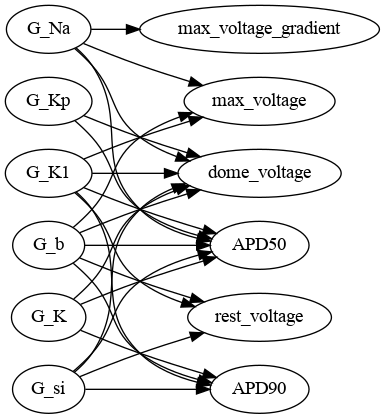

In [2]:
from causal_testing.specification.causal_dag import CausalDAG

from tutorial_utils import render_dag


dag = CausalDAG(lr91.dag_path)
render_dag(dag)

Since we're only interested in APD90, let's zoom in on the part of the DAG that matters, namely the six conductances and
APD90.

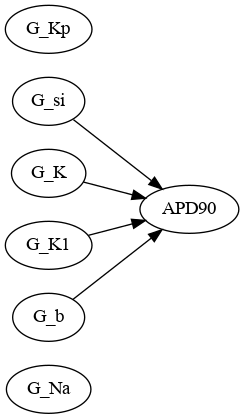

In [3]:
apd90_dag = dag.subgraph(lr91.conductances + ["APD90"])
render_dag(apd90_dag)

This matches Figure 5 in the paper. Four of the conductances have an arrow into APD90, while `G_Na` and `G_Kp` have
none, which states our expectation (MR3) that they have no effect on it. We could have left them out of the DAG
altogether, but including them makes that expectation explicit.

Notice that there are no arrows *between* the inputs. Each conductance was sampled independently of the others, so
none of them can cause another. Building this DAG took very little effort, since the expected relationships come
straight from the earlier study.

## Step 2: The data

We reuse the data-generation approach of Chang et al. 200 input configurations were sampled from the design
distributions using [Latin hypercube sampling](https://en.wikipedia.org/wiki/Latin_hypercube_sampling), which spreads
the samples evenly across the input space. Each configuration was then run through a
[Python implementation of LR91](https://github.com/AndrewC19/LR91/tree/769e7ff), and the outputs recorded.

The raw results are available as `lr91.raw_df`:

In [4]:
raw_df = lr91.raw_df
raw_df

,G_Na,G_si,G_K,G_K1,G_Kp,G_b,max_voltage,rest_voltage,max_voltage_gradient,dome_voltage,APD50,APD90
0,26.199775,0.099833,0.304337,0.560154,0.017205,0.040096,50.247580,-83.682213,365.598494,13.310458,264,374
1,24.562412,0.074341,0.243847,0.471056,0.021965,0.048051,49.980801,-82.451705,345.391741,2.124089,190,311
2,22.935163,0.096957,0.255353,0.706541,0.014284,0.047722,46.465792,-84.136274,339.090985,10.875964,261,359
3,18.377754,0.075971,0.308701,0.689066,0.019648,0.039383,41.006660,-84.721861,289.482850,41.006660,228,300
4,18.121539,0.083495,0.243972,0.537462,0.015575,0.047380,42.607650,-83.102082,289.071884,6.865519,238,339
...,...,...,...,...,...,...,...,...,...,...,...,...
195,19.213961,0.070938,0.236367,0.662578,0.014118,0.037989,42.408708,-84.731573,299.184390,42.408708,246,325
196,19.161498,0.092812,0.213698,0.574407,0.014442,0.032851,42.914890,-84.340590,310.821649,42.914890,344,453
197,20.345926,0.074099,0.315313,0.580985,0.015276,0.031933,44.112649,-84.681263,322.068374,44.112649,241,320
198,19.447035,0.095274,0.279124,0.547402,0.013924,0.038713,43.858393,-83.731423,307.230620,43.858393,284,383


Each row is one run of the model. The first six columns are the conductances (inputs), and the rest are outputs that
describe the action potential. As planned, we normalise each conductance to the range $[0, 1]$ using the smallest
and largest values in the data:

In [5]:
df = raw_df.copy()
inputs = df[lr91.conductances]
df[lr91.conductances] = (inputs - inputs.min()) / (inputs.max() - inputs.min())

# This is exactly the pre-normalised data that is also shipped with the CTF as `lr91.df`
pd.testing.assert_frame_equal(df.reset_index(drop=True), lr91.df)

df[lr91.conductances + ["APD90"]].describe().round(3)

,G_Na,G_si,G_K,G_K1,G_Kp,G_b,APD90
count,200.000,200.000,200.000,200.000,200.000,200.000,200.000
mean,0.501,0.499,0.500,0.499,0.500,0.500,362.915
std,0.291,0.291,0.291,0.291,0.291,0.290,53.130
min,0.000,0.000,0.000,0.000,0.000,0.000,250.000
25%,0.252,0.249,0.250,0.248,0.248,0.251,325.000
50%,0.502,0.499,0.501,0.499,0.501,0.500,358.000
75%,0.752,0.752,0.751,0.750,0.751,0.749,400.000
max,1.000,1.000,1.000,1.000,1.000,1.000,501.000


Before going further, it's worth a quick look at the data. A scatter plot of APD90 against each input gives us an
early idea of what to expect:

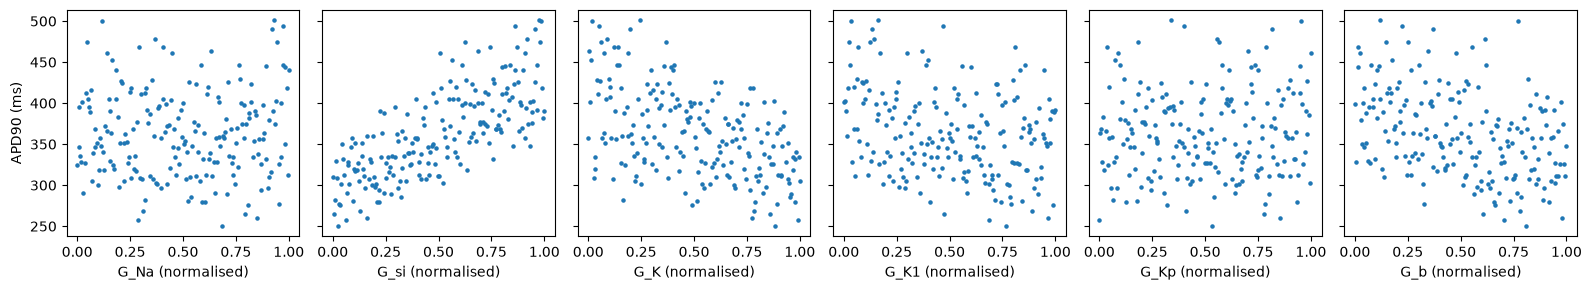

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 6, figsize=(16, 3), sharey=True)
for ax, conductance in zip(axes, lr91.conductances):
    ax.scatter(df[conductance], df["APD90"], s=5)
    ax.set_xlabel(f"{conductance} (normalised)")
axes[0].set_ylabel("APD90 (ms)")
plt.tight_layout()
plt.show()

There's clearly a strong upward trend for `G_si` and downward trends for `G_K`, `G_b`, and `G_K1`. There's no obvious
pattern for `G_Na` and `G_Kp`. The plots are noisy, though, because all six inputs vary at the same time. Causal testing
lets us put proper numbers (with confidence intervals) on what we see here.

## Step 3: Defining the causal test cases

We measure the effect of each input using the **average treatment effect** (ATE). This is the expected change in
APD90 when we change an input from a *control* value $c$ to a *treatment* value $t$:

$$ATE = \mathbb{E}[\text{APD90} \mid G = t] - \mathbb{E}[\text{APD90} \mid G = c]$$

To mimic the original sensitivity analysis, we set the control value to the middle of the range, $c = 0.5$. We then
move the treatment value across the whole range, $t \in \{0, 0.1, 0.2, \dots, 1.0\}$. We skip $t = 0.5$, since
"changing" the input from 0.5 to 0.5 is not a change at all. That gives **10 causal test cases per input**, or 60 in
total.

For each test we also need an **expected causal effect**, which acts as the test oracle. We need to be a little
careful here. MR1 says that *increasing* `G_K` should *decrease* APD90. So when $t > 0.5$ we expect a negative ATE,
but when $t < 0.5$ we are *decreasing* `G_K` and so we expect a *positive* ATE. The CTF provides the following expected
effects:

* `Positive()` passes if the whole 95% confidence interval of the ATE is above zero;
* `Negative()` passes if the whole 95% confidence interval is below zero;
* `NoEffect()` passes if the 95% confidence interval contains zero.

Let's write a small helper that picks the right oracle for each test, based on the expected direction of the effect
of *increasing* each input.

In [7]:
import numpy as np

from causal_testing.testing.causal_effect import Negative, NoEffect, Positive

# The expected effect on APD90 of *increasing* each input: +1 increase, -1 decrease, 0 no effect.
expected_direction = {
    "G_K": -1,  # MR1
    "G_b": -1,  # MR1
    "G_K1": -1,  # MR1
    "G_si": +1,  # MR2
    "G_Na": 0,  # MR3
    "G_Kp": 0,  # MR3
}


def expected_effect(conductance, control_value, treatment_value):
    # If we're decreasing the input, the expected direction of the effect flips
    direction = expected_direction[conductance] * np.sign(treatment_value - control_value)
    if direction > 0:
        return Positive()
    if direction < 0:
        return Negative()
    return NoEffect()


control_value = 0.5
treatment_values = [float(t) for t in np.round(np.linspace(0, 1, 11), 1) if t != control_value]
treatment_values

[0.0, 0.1, 0.2, 0.3, 0.4, 0.6, 0.7, 0.8, 0.9, 1.0]

## Step 4: Identification

Before estimating anything, we need to know whether the effect of each input on APD90 is **confounded**. A confounder
is a variable that affects both the input and the output, and would make the raw relationship between them
misleading. The CTF uses the DAG to find the smallest set of variables we need to adjust for:

In [8]:
{conductance: dag.identification(conductance, "APD90") for conductance in lr91.conductances}

{'G_Na': set(),
 'G_si': set(),
 'G_K': set(),
 'G_K1': set(),
 'G_Kp': set(),
 'G_b': set()}

Every adjustment set is empty, so **there is no confounding to deal with**. This makes sense. Nothing in the DAG
causes any of the inputs, so the only way an input can be associated with APD90 is by causing it.

## Step 5: Estimation

Because there's nothing to adjust for, we can use a very simple regression model for each input $G_z$:

$$\text{APD90} \sim \beta_0 + \beta_1 G_z$$

That is, a straight line relating the input to APD90. The other inputs vary in the data too, but because they don't
confound the relationship we're interested in, leaving them out won't bias our estimate. They just add some noise.
Compare this with the original study, which needed a Gaussian Process Emulator. That's a much more complex model that
requires choosing a suitable kernel and scales poorly to large datasets.

The `LinearRegressionEstimator` builds this model for us when we pass it the adjustment set from identification.

## Step 6: Running the tests

Now we can put it all together and run the 60 causal test cases.

In [9]:
from causal_testing.estimation.linear_regression_estimator import LinearRegressionEstimator
from causal_testing.testing.causal_test_case import CausalTestCase

results = []
for conductance in lr91.conductances:
    adjustment_set = dag.identification(conductance, "APD90")
    for treatment_value in treatment_values:
        estimator = LinearRegressionEstimator(
            treatment_variable=conductance,
            outcome_variable="APD90",
            control_value=control_value,
            treatment_value=treatment_value,
            adjustment_set=adjustment_set,
            alpha=0.05,  # i.e. compute 95% confidence intervals
        )
        test_case = CausalTestCase(
            expected_causal_effect=expected_effect(conductance, control_value, treatment_value),
            effect_measure="ate",
            estimator=estimator,
        )
        test_case.execute_test(df)

        estimate = test_case.result.effect_estimate
        results.append(
            {
                "input": conductance,
                "treatment_value": treatment_value,
                "expected": str(test_case.expected_causal_effect),
                "ate": estimate.effect_estimate.iloc[0],
                "ci_low": estimate.ci_low.iloc[0],
                "ci_high": estimate.ci_high.iloc[0],
                "outcome": test_case.result.outcome.name,
            }
        )

results = pd.DataFrame(results)
results.round(3)

,input,treatment_value,expected,ate,ci_low,ci_high,outcome
0,G_Na,0.0,NoEffect,-2.988,-15.784,9.809,PASS
1,G_Na,0.1,NoEffect,-2.390,-12.627,7.847,PASS
2,G_Na,0.2,NoEffect,-1.793,-9.470,5.885,PASS
3,G_Na,0.3,NoEffect,-1.195,-6.313,3.923,PASS
4,G_Na,0.4,NoEffect,-0.598,-3.157,1.962,PASS
5,G_Na,0.6,NoEffect,0.598,-1.962,3.157,PASS
6,G_Na,0.7,NoEffect,1.195,-3.923,6.313,PASS
7,G_Na,0.8,NoEffect,1.793,-5.885,9.470,PASS
8,G_Na,0.9,NoEffect,2.390,-7.847,12.627,PASS
9,G_Na,1.0,NoEffect,2.988,-9.809,15.784,PASS


Each row is one causal test. `ate` is the estimated change in APD90 (in ms) when the input moves from 0.5 to
`treatment_value`, and `ci_low` and `ci_high` give its 95% confidence interval. Let's summarise the outcomes for each
input:

In [10]:
results.groupby("input")["outcome"].value_counts().unstack(fill_value=0)

outcome,PASS
input,
G_K,10
G_K1,10
G_Kp,10
G_Na,10
G_b,10
G_si,10


**All 60 tests pass.** MR1, MR2, and MR3 hold over the whole range of each input:

* increasing `G_K`, `G_b`, or `G_K1` decreases APD90, and decreasing them increases it;
* increasing `G_si` increases APD90;
* `G_Na` and `G_Kp` have no statistically significant effect.

We can visualise these results in the same way as Figure 6 of the paper. Each line shows the estimated ATE as we move
an input away from its mean value, and the shaded bands show the 95% confidence intervals.

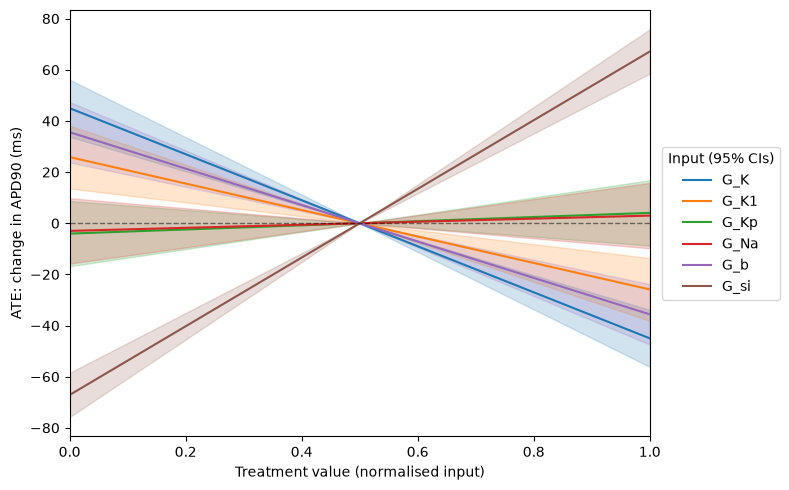

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
for conductance, group in results.groupby("input"):
    # Add the control value itself (ATE = 0) so the lines pass through the mean
    group = pd.concat(
        [group, pd.DataFrame([{"treatment_value": control_value, "ate": 0, "ci_low": 0, "ci_high": 0}])]
    ).sort_values("treatment_value")
    (line,) = ax.plot(group["treatment_value"], group["ate"], label=conductance)
    ax.fill_between(group["treatment_value"], group["ci_low"], group["ci_high"], alpha=0.2, color=line.get_color())
ax.axhline(0, color="black", linestyle="--", linewidth=1, alpha=0.5)
ax.set_xlabel("Treatment value (normalised input)")
ax.set_ylabel("ATE: change in APD90 (ms)")
ax.set_xlim(0, 1)
ax.legend(title="Input (95% CIs)", loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.show()

### MR4: comparing the size of the effects

MR4 is about the *relative size* of the effects, not their direction. Because our regression model is a straight line,
the effect of each input is fully summarised by its slope (the coefficient $\beta_1$). This is the change in APD90
caused by moving the input from the bottom of its range to the top. The steeper the slope, the more sensitive APD90 is
to that input.

The CTF can estimate this directly using the `coefficient` effect measure. We don't need control and treatment values
here, because the coefficient describes the effect of the input across its whole range. For each input we use the same
expected effect as before, i.e. the effect of increasing it.

In [12]:
coefficients = []
for conductance in lr91.conductances:
    test_case = CausalTestCase(
        expected_causal_effect=expected_effect(conductance, control_value=0, treatment_value=1),
        effect_measure="coefficient",
        estimator=LinearRegressionEstimator(
            treatment_variable=conductance,
            outcome_variable="APD90",
            adjustment_set=dag.identification(conductance, "APD90"),
        ),
    )
    test_case.execute_test(df)
    estimate = test_case.result.effect_estimate
    coefficients.append(
        {
            "input": conductance,
            "coefficient": estimate.effect_estimate.iloc[0],
            "ci_low": estimate.ci_low.iloc[0],
            "ci_high": estimate.ci_high.iloc[0],
            "outcome": test_case.result.outcome.name,
        }
    )

coefficients = pd.DataFrame(coefficients).set_index("input")
coefficients["magnitude"] = coefficients["coefficient"].abs()
coefficients.sort_values("magnitude", ascending=False).round(3)

,coefficient,ci_low,ci_high,outcome,magnitude
input,,,,,
G_si,134.285,116.968,151.603,PASS,134.285
G_K,-89.983,-112.267,-67.699,PASS,89.983
G_b,-71.222,-94.868,-47.576,PASS,71.222
G_K1,-51.750,-76.312,-27.187,PASS,51.750
G_Kp,8.106,-17.475,33.686,PASS,8.106
G_Na,5.975,-19.617,31.567,PASS,5.975


Finally, let's check that the inputs with an expected effect appear in the order MR4 predicts:

In [13]:
expected_order = ["G_si", "G_K", "G_b", "G_K1"]
observed_order = coefficients.loc[expected_order, "magnitude"].sort_values(ascending=False).index.tolist()

print("Expected order:", " > ".join(expected_order))
print("Observed order:", " > ".join(observed_order))
print("MR4 holds:", observed_order == expected_order)

Expected order: G_si > G_K > G_b > G_K1
Observed order: G_si > G_K > G_b > G_K1
MR4 holds: True


MR4 holds too: `G_si` has the largest effect on APD90, followed by `G_K`, `G_b`, and `G_K1`.

Note that the confidence intervals of neighbouring coefficients overlap somewhat (e.g. `G_K` and `G_b`). So while the
*estimated* ordering matches our expectation, we'd need more data to say with high confidence that, for example,
`G_K` has a strictly larger effect than `G_b`.

## Summary

In this tutorial we used the CTF to carry out a sensitivity analysis of the LR91 cardiac action potential model:

1. We turned the findings of an earlier study into four **metamorphic relations** about the effect of six
   conductances on APD90.
2. We wrote down a simple **causal DAG** and used **identification** to show that none of the effects are
   confounded.
3. This meant each effect could be estimated with a **simple linear regression**. In the original study, a far more
   complex Gaussian Process Emulator was needed.
4. We ran 60 **causal test cases** covering changes across the whole range of each input, plus a comparison of effect
   sizes.

All four metamorphic relations hold, so we reached **the same conclusions as the original study**. The difference is
that our statistical model was chosen by reasoning about cause and effect rather than by fitting a black box to the
data. This makes the results easier to explain and justify.

In terms of effort, the DAG was straightforward to build, since the relationships we needed came directly from the
earlier study. Because we reused the original study's data generation approach (200 runs), this case study doesn't
tell us much about how *data-efficient* the CTF is. For that, see the
[Poisson Line Tessellation case study](poisson_line_tessellation.ipynb).

## Further resources

* [Testing Causality in Scientific Modelling Software (paper)](https://dl.acm.org/doi/10.1145/3607184)
* C. H. Luo and Y. Rudy, "A model of the ventricular cardiac action potential. Depolarization, repolarization, and
  their interaction", *Circulation Research* 68(6), pp. 1501–1526, 1991.
* E. T. Y. Chang, M. Strong, and R. H. Clayton, "Bayesian sensitivity analysis of a cardiac cell model using a
  Gaussian process emulator", *PLoS ONE* 10(6), e0130252, 2015.
* [Python implementation of LR91 used to generate the data](https://github.com/AndrewC19/LR91/tree/769e7ff)
* [Causal Testing Framework on GitHub](https://github.com/CITCOM-project/CausalTestingFramework)
* [Causal Testing Framework documentation](https://causal-testing-framework.readthedocs.io/en/latest/index.html)